<a href="https://colab.research.google.com/github/ashishbishnoi023/BlinkIT_Sales_Analysis/blob/main/BlinkIT_Sales_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BlinkIT Grocery Sales Analysis
Project for Sapphire IQ (Retail & Grocery Sales Analytics)

Tools: Python, Pandas, NumPy, Matplotlib, Seaborn

In [52]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [53]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [54]:
df = pd.read_excel("/content/BlinkIT Grocery Data.xlsx")
print(df.shape)
df.head()

(8523, 12)


,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
0,Regular,FDX32,Fruits and Vegetables,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.100014,15.10,145.4786,5.0
1,Low Fat,NCB42,Health and Hygiene,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.008596,11.80,115.3492,5.0
2,Regular,FDR28,Frozen Foods,2016,OUT046,Tier 1,Small,Supermarket Type1,0.025896,13.85,165.0210,5.0
3,Regular,FDL50,Canned,2014,OUT013,Tier 3,High,Supermarket Type1,0.042278,12.15,126.5046,5.0
4,Low Fat,DRI25,Soft Drinks,2015,OUT045,Tier 2,Small,Supermarket Type1,0.033970,19.60,55.1614,5.0


## Objective 1: Understanding the business

### Task 1.1 - Products

In [55]:
df.info()
print()
print("Unique items:", df["Item Identifier"].nunique())
print("Item types:", df["Item Type"].nunique())
print(df["Item Type"].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item Fat Content           8523 non-null   object 
 1   Item Identifier            8523 non-null   object 
 2   Item Type                  8523 non-null   object 
 3   Outlet Establishment Year  8523 non-null   int64  
 4   Outlet Identifier          8523 non-null   object 
 5   Outlet Location Type       8523 non-null   object 
 6   Outlet Size                8523 non-null   object 
 7   Outlet Type                8523 non-null   object 
 8   Item Visibility            8523 non-null   float64
 9   Item Weight                7060 non-null   float64
 10  Sales                      8523 non-null   float64
 11  Rating                     8523 non-null   float64
dtypes: float64(4), int64(1), object(7)
memory usage: 799.2+ KB

Unique items: 1559
Item types: 16
Item Type


### Task 1.2 - Outlets

In [56]:
print(df["Outlet Identifier"].nunique(), "outlets")
print(df["Outlet Type"].value_counts())
print()
print(df["Outlet Size"].value_counts())
print()
print(df["Outlet Location Type"].value_counts())

10 outlets
Outlet Type
Supermarket Type1    5577
Grocery Store        1083
Supermarket Type3     935
Supermarket Type2     928
Name: count, dtype: int64

Outlet Size
Medium    3631
Small     3139
High      1753
Name: count, dtype: int64

Outlet Location Type
Tier 3    3350
Tier 2    2785
Tier 1    2388
Name: count, dtype: int64


In [57]:
# one row per outlet to see what each outlet looks like
df.groupby("Outlet Identifier")[["Outlet Type", "Outlet Size", "Outlet Location Type", "Outlet Establishment Year"]].first()

,Outlet Type,Outlet Size,Outlet Location Type,Outlet Establishment Year
Outlet Identifier,,,,
OUT010,Grocery Store,Small,Tier 3,2011
OUT013,Supermarket Type1,High,Tier 3,2014
OUT017,Supermarket Type1,Small,Tier 2,2020
OUT018,Supermarket Type2,Medium,Tier 3,2022
OUT019,Grocery Store,Small,Tier 1,2018
OUT027,Supermarket Type3,Medium,Tier 3,2018
OUT035,Supermarket Type1,Small,Tier 2,2017
OUT045,Supermarket Type1,Small,Tier 2,2015
OUT046,Supermarket Type1,Small,Tier 1,2016


### Task 1.3 - Overall sales

Total sales: 1201681.49
Average sales: 140.99
Highest: 266.8884
Lowest: 31.29


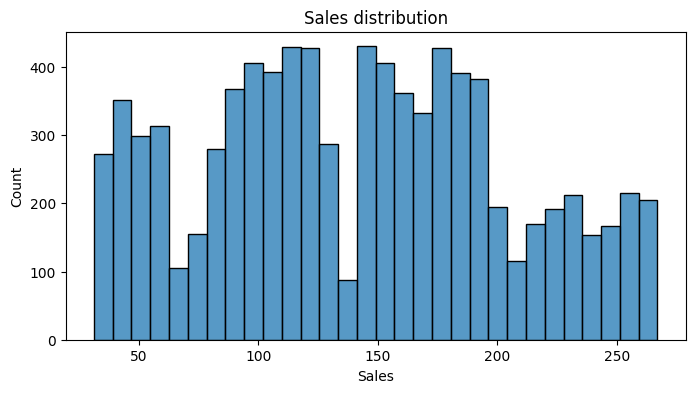

In [58]:
print("Total sales:", round(df["Sales"].sum(), 2))
print("Average sales:", round(df["Sales"].mean(), 2))
print("Highest:", df["Sales"].max())
print("Lowest:", df["Sales"].min())

plt.figure(figsize=(8, 4))
sns.histplot(df["Sales"], bins=30)
plt.title("Sales distribution")
plt.show()

### Task 1.4 - Ratings

Average rating: 3.97


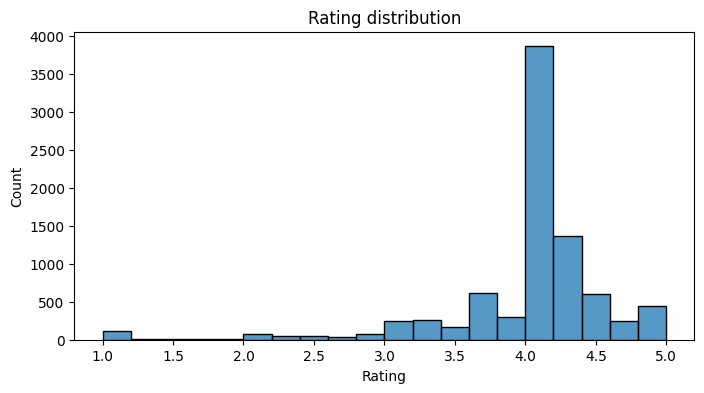

,Rating
Item Type,
Breads,3.881275
Hard Drinks,3.907477
Starchy Foods,3.920270
Soft Drinks,3.920674
Breakfast,3.932727
Snack Foods,3.948917
Others,3.954438
Fruits and Vegetables,3.956169
Seafood,3.959375


In [59]:
print("Average rating:", round(df["Rating"].mean(), 2))

plt.figure(figsize=(8, 4))
sns.histplot(df["Rating"], bins=20)
plt.title("Rating distribution")
plt.show()

df.groupby("Item Type")["Rating"].mean().sort_values()

**Observations (Objective 1)**
- The data has 8523 rows and 12 columns, with 1559 different items sold across 16 item types and 10 outlets.
- Total sales is about 1.2 million and the average sale is about 141.
- Average rating is 3.97, and most ratings are between 3.5 and 4.5. Average rating of every item type is almost the same (3.88 to 4.02).

## Objective 2: Checking data quality

### Task 2.1 - Missing values

In [60]:
print(df.isnull().sum())
print()
print("Item Visibility = 0 :", (df["Item Visibility"] == 0).sum(), "rows")

Item Fat Content                0
Item Identifier                 0
Item Type                       0
Outlet Establishment Year       0
Outlet Identifier               0
Outlet Location Type            0
Outlet Size                     0
Outlet Type                     0
Item Visibility                 0
Item Weight                  1463
Sales                           0
Rating                          0
dtype: int64

Item Visibility = 0 : 526 rows


### Task 2.2 - Duplicates

In [61]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


### Task 2.3 - Outliers

Item Visibility -> 144 outliers
Item Weight -> 0 outliers
Sales -> 0 outliers
Rating -> 1931 outliers


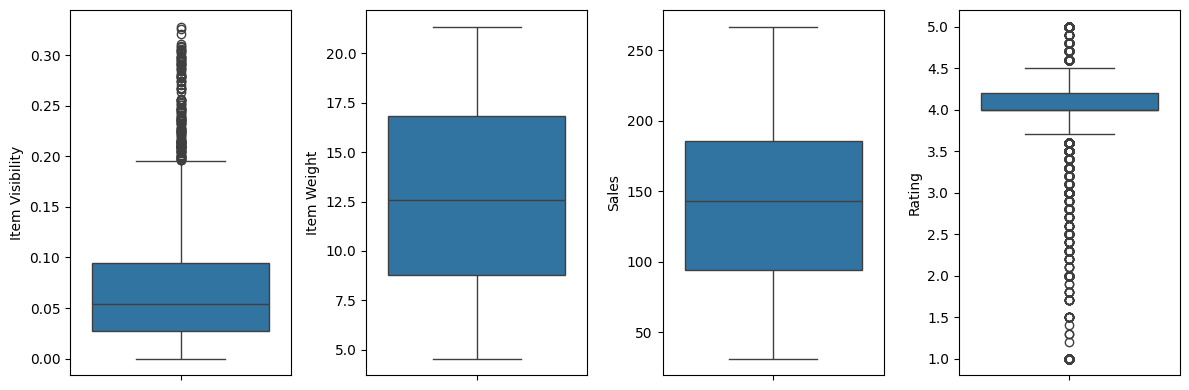

In [62]:
cols = ["Item Visibility", "Item Weight", "Sales", "Rating"]

for c in cols:
    q1 = df[c].quantile(0.25)
    q3 = df[c].quantile(0.75)
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr
    count = ((df[c] < low) | (df[c] > high)).sum()
    print(c, "->", count, "outliers")

plt.figure(figsize=(12, 4))
for i, c in enumerate(cols):
    plt.subplot(1, 4, i + 1)
    sns.boxplot(y=df[c])
plt.tight_layout()
plt.show()

### Task 2.4 - Cleaning

In [63]:
# Item Fat Content has the same thing written in different ways
print(df["Item Fat Content"].value_counts())

Item Fat Content
Low Fat    5089
Regular    2889
LF          316
reg         117
low fat     112
Name: count, dtype: int64


In [64]:
df["Item Fat Content"] = df["Item Fat Content"].replace({"LF": "Low Fat", "low fat": "Low Fat", "reg": "Regular"})
print(df["Item Fat Content"].value_counts())

Item Fat Content
Low Fat    5517
Regular    3006
Name: count, dtype: int64


In [65]:
# Item Weight missing -> fill with average weight of the same item,
# and if the item has no weight anywhere use the average of its item type
df["Item Weight"] = df["Item Weight"].fillna(df.groupby("Item Identifier")["Item Weight"].transform("mean"))
df["Item Weight"] = df["Item Weight"].fillna(df.groupby("Item Type")["Item Weight"].transform("mean"))

# visibility can't really be 0 for a product that is sold, so replace with item average
df["Item Visibility"] = df["Item Visibility"].replace(0, np.nan)
df["Item Visibility"] = df["Item Visibility"].fillna(df.groupby("Item Identifier")["Item Visibility"].transform("mean"))
df["Item Visibility"] = df["Item Visibility"].fillna(df["Item Visibility"].mean())

print(df.isnull().sum())

Item Fat Content             0
Item Identifier              0
Item Type                    0
Outlet Establishment Year    0
Outlet Identifier            0
Outlet Location Type         0
Outlet Size                  0
Outlet Type                  0
Item Visibility              0
Item Weight                  0
Sales                        0
Rating                       0
dtype: int64


**Observations (Objective 2)**
- Only `Item Weight` had missing values (1463 rows). I filled them using the average weight of the same item.
- `Item Visibility` had 526 rows with value 0 which is not realistic, so I replaced them with the item's average visibility.
- There are no duplicate rows.
- `Item Visibility` has 144 outliers (very high visibility). I kept them because they look like genuine values and not mistakes. Sales and Rating have no outliers.
- `Item Fat Content` had 5 labels (Low Fat, low fat, LF, Regular, reg) which I merged into 2: Low Fat and Regular.

## Objective 3: What drives sales?

### Task 3.1 - Product types

                               sum        mean
Item Type                                     
Fruits and Vegetables  178124.0810  144.581235
Snack Foods            175433.9224  146.194935
Household              135976.5254  149.424753
Frozen Foods           118558.8814  138.503366
Dairy                  101276.4616  148.499211
Canned                  90706.7290  139.763835
Baking Goods            81894.7364  126.380766
Health and Hygiene      68025.8388  130.818921
Meat                    59449.8638  139.882032
Soft Drinks             58514.1670  131.492510
Breads                  35379.1198  140.952669
Hard Drinks             29334.6806  137.077947
Others                  22451.8916  132.851430
Starchy Foods           21880.0274  147.838023
Breakfast               15596.6966  141.788151
Seafood                  9077.8700  141.841719


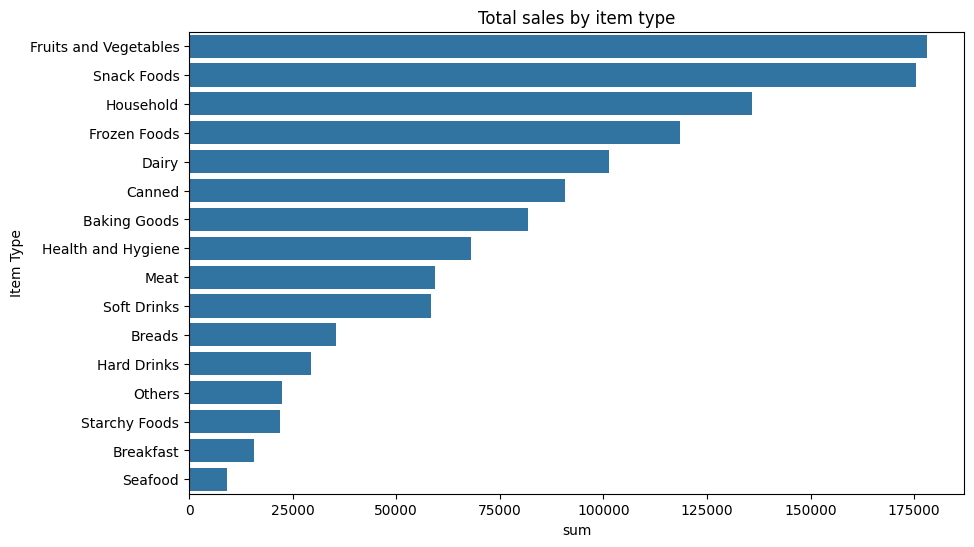

In [66]:
item_sales = df.groupby("Item Type")["Sales"].agg(["sum", "mean"]).sort_values("sum", ascending=False)
print(item_sales)

plt.figure(figsize=(10, 6))
sns.barplot(x=item_sales["sum"], y=item_sales.index)
plt.title("Total sales by item type")
plt.show()

Item Fat Content
Low Fat    776319.6884
Regular    425361.8044
Name: Sales, dtype: float64


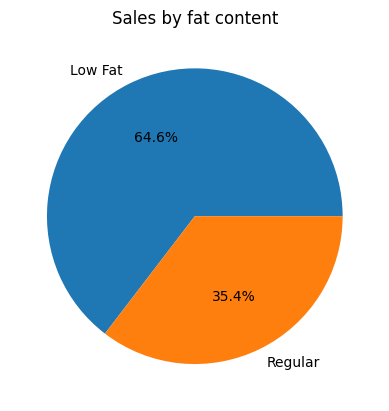

In [67]:
print(df.groupby("Item Fat Content")["Sales"].sum())

df.groupby("Item Fat Content")["Sales"].sum().plot(kind="pie", autopct="%1.1f%%")
plt.title("Sales by fat content")
plt.ylabel("")
plt.show()

### Task 3.2 - Outlets

In [68]:
for col in ["Outlet Type", "Outlet Size", "Outlet Location Type"]:
    print(df.groupby(col)["Sales"].agg(["sum", "mean", "count"]))
    print()

                           sum        mean  count
Outlet Type                                      
Grocery Store      151939.1490  140.294690   1083
Supermarket Type1  787549.8928  141.213895   5577
Supermarket Type2  131477.7764  141.678638    928
Supermarket Type3  130714.6746  139.801791    935

                     sum        mean  count
Outlet Size                                
High         248991.5860  142.037414   1753
Medium       507895.7364  139.877647   3631
Small        444794.1704  141.699322   3139

                              sum        mean  count
Outlet Location Type                                
Tier 1                336397.8120  140.870106   2388
Tier 2                393150.6476  141.167198   2785
Tier 3                472133.0332  140.935234   3350



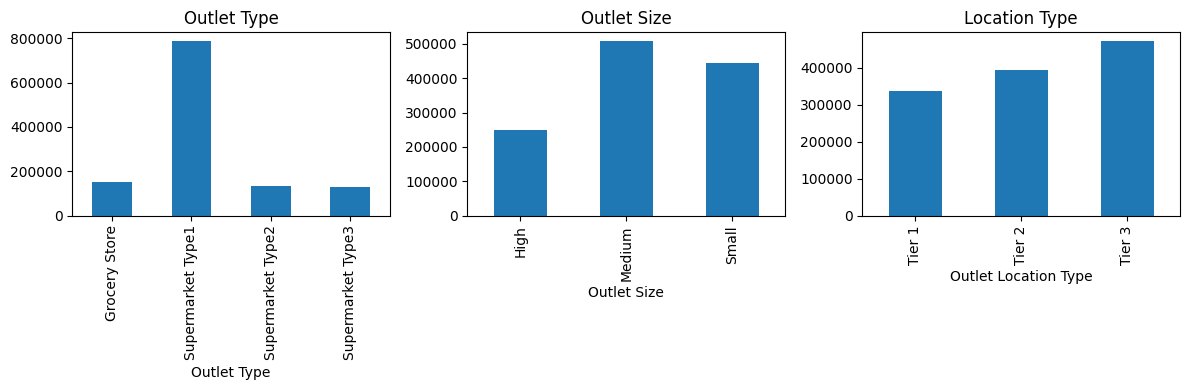

In [69]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
df.groupby("Outlet Type")["Sales"].sum().plot(kind="bar")
plt.title("Outlet Type")

plt.subplot(1, 3, 2)
df.groupby("Outlet Size")["Sales"].sum().plot(kind="bar")
plt.title("Outlet Size")

plt.subplot(1, 3, 3)
df.groupby("Outlet Location Type")["Sales"].sum().plot(kind="bar")
plt.title("Location Type")

plt.tight_layout()
plt.show()

Outlet Identifier
OUT035    133103.9070
OUT046    132113.3698
OUT013    131809.0156
OUT018    131477.7764
OUT045    130942.7802
OUT027    130714.6746
OUT049    130476.8598
OUT017    129103.9604
OUT010     78131.5666
OUT019     73807.5824
Name: Sales, dtype: float64


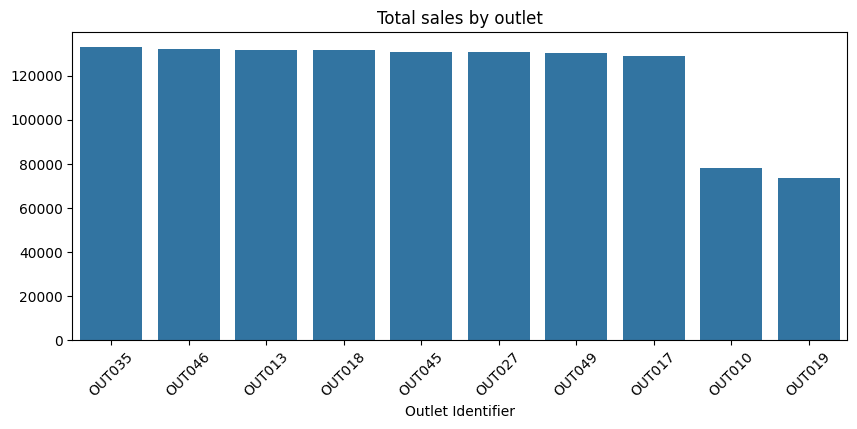

In [70]:
outlet_sales = df.groupby("Outlet Identifier")["Sales"].sum().sort_values(ascending=False)
print(outlet_sales)

plt.figure(figsize=(10, 4))
sns.barplot(x=outlet_sales.index, y=outlet_sales.values)
plt.title("Total sales by outlet")
plt.xticks(rotation=45)
plt.show()

In [71]:
print(df.groupby("Outlet Establishment Year")["Sales"].sum())

Outlet Establishment Year
2011     78131.5666
2012    130476.8598
2014    131809.0156
2015    130942.7802
2016    132113.3698
2017    133103.9070
2018    204522.2570
2020    129103.9604
2022    131477.7764
Name: Sales, dtype: float64


### Task 3.3 - Visibility, weight, rating and sales

                 Item Visibility  Item Weight    Rating     Sales
Item Visibility         1.000000    -0.021226 -0.003884 -0.005951
Item Weight            -0.021226     1.000000  0.004389  0.025967
Rating                 -0.003884     0.004389  1.000000  0.011329
Sales                  -0.005951     0.025967  0.011329  1.000000


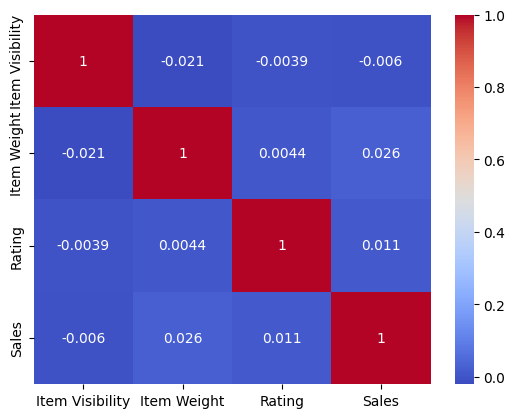

In [72]:
print(df[["Item Visibility", "Item Weight", "Rating", "Sales"]].corr())

sns.heatmap(df[["Item Visibility", "Item Weight", "Rating", "Sales"]].corr(), annot=True, cmap="coolwarm")
plt.show()

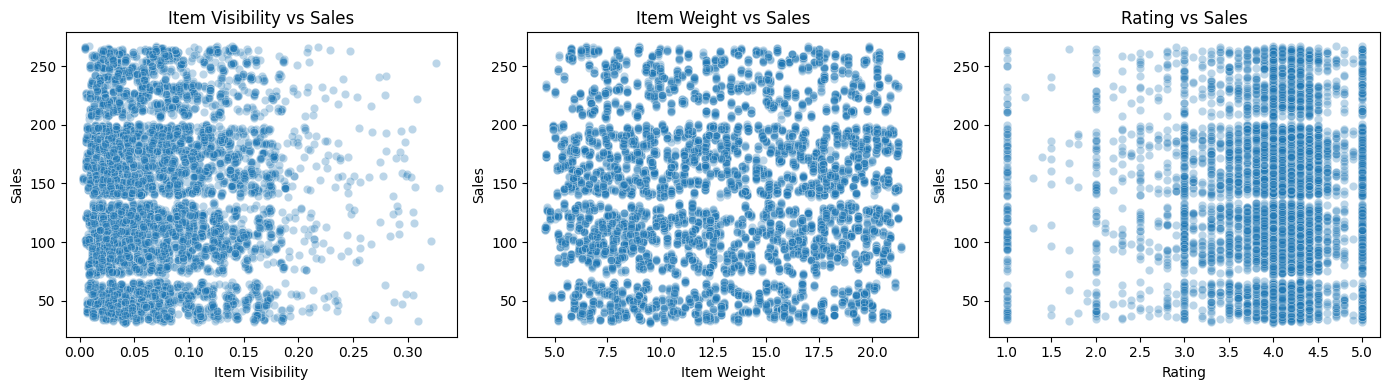

In [73]:
plt.figure(figsize=(14, 4))
for i, c in enumerate(["Item Visibility", "Item Weight", "Rating"]):
    plt.subplot(1, 3, i + 1)
    sns.scatterplot(x=df[c], y=df["Sales"], alpha=0.3)
    plt.title(c + " vs Sales")
plt.tight_layout()
plt.show()

### Task 3.4 - Better vs lower performing

In [74]:
# top 5 and bottom 5 item types
print("Top 5")
print(item_sales.head(5))
print()
print("Bottom 5")
print(item_sales.tail(5))

Top 5
                               sum        mean
Item Type                                     
Fruits and Vegetables  178124.0810  144.581235
Snack Foods            175433.9224  146.194935
Household              135976.5254  149.424753
Frozen Foods           118558.8814  138.503366
Dairy                  101276.4616  148.499211

Bottom 5
                      sum        mean
Item Type                            
Hard Drinks    29334.6806  137.077947
Others         22451.8916  132.851430
Starchy Foods  21880.0274  147.838023
Breakfast      15596.6966  141.788151
Seafood         9077.8700  141.841719


In [75]:
# comparing the outlets
outlet_compare = df.groupby(["Outlet Identifier", "Outlet Type", "Outlet Size", "Outlet Location Type"])["Sales"].agg(["sum", "mean", "count"])
outlet_compare.sort_values("sum", ascending=False)

,,,,sum,mean,count
Outlet Identifier,Outlet Type,Outlet Size,Outlet Location Type,,,
OUT035,Supermarket Type1,Small,Tier 2,133103.9070,143.122481,930
OUT046,Supermarket Type1,Small,Tier 1,132113.3698,142.057387,930
OUT013,Supermarket Type1,High,Tier 3,131809.0156,141.425982,932
OUT018,Supermarket Type2,Medium,Tier 3,131477.7764,141.678638,928
OUT027,Supermarket Type3,Medium,Tier 3,130714.6746,139.801791,935
OUT049,Supermarket Type1,Medium,Tier 1,130476.8598,140.297699,930
OUT019,Grocery Store,Small,Tier 1,73807.5824,139.787088,528
OUT017,Supermarket Type1,Small,Tier 2,50121.8602,136.200707,368
OUT045,Supermarket Type1,Small,Tier 2,47264.1186,144.981959,326


**Observations (Objective 3)**
- Fruits and Vegetables (178k) and Snack Foods (175k) are the top two item types, followed by Household (136k). Seafood (9k) and Breakfast (16k) are the lowest.
- Low Fat products give about 65% of the total sales and Regular about 35%.
- Supermarket Type1 has the highest total sales (788k), but it also has 5 outlets, while the other types have 1 or 2. Average sales per row is almost the same for all outlet types (about 140 to 142), so Type1 is higher mostly because of more outlets and records.
- Tier 3 has the highest sales (472k), then Tier 2 (393k) and Tier 1 (336k). Medium size outlets sell the most in total (508k).
- The two Grocery Stores (OUT010 and OUT019) have the lowest sales of all outlets (about 78k and 74k), compared to about 130k for most other outlets.
- Correlation of sales with visibility, weight and rating is almost 0 (between -0.001 and 0.027), so none of them has a clear relation with sales in this data. Higher rating does not mean higher sales.

## Objective 4: Business decisions

### Task 4.1 - Products contributing more to sales

In [76]:
total = df["Sales"].sum()
share = (item_sales["sum"] / total * 100).round(2)
print(share)
print()
print("Top 5 types share:", round(share.head(5).sum(), 2), "%")

Item Type
Fruits and Vegetables    14.82
Snack Foods              14.60
Household                11.32
Frozen Foods              9.87
Dairy                     8.43
Canned                    7.55
Baking Goods              6.82
Health and Hygiene        5.66
Meat                      4.95
Soft Drinks               4.87
Breads                    2.94
Hard Drinks               2.44
Others                    1.87
Starchy Foods             1.82
Breakfast                 1.30
Seafood                   0.76
Name: sum, dtype: float64

Top 5 types share: 59.04 %


In [77]:
top_items = df.groupby("Item Identifier")["Sales"].sum().sort_values(ascending=False).head(10)
print(top_items)

Item Identifier
FDU12    2371.0112
FDT07    2306.8970
NCQ06    2294.7126
FDL58    2111.6544
NCB31    2104.7280
FDX31    2104.4622
FDF05    2103.1280
FDR59    2096.5752
FDP28    2087.8488
FDA04    2072.0696
Name: Sales, dtype: float64


### Task 4.2 - Better outlets and locations

In [78]:
print(outlet_sales.head(3))
print()
print(df.groupby("Outlet Location Type")["Sales"].sum().sort_values(ascending=False))

Outlet Identifier
OUT035    133103.9070
OUT046    132113.3698
OUT013    131809.0156
Name: Sales, dtype: float64

Outlet Location Type
Tier 3    472133.0332
Tier 2    393150.6476
Tier 1    336397.8120
Name: Sales, dtype: float64


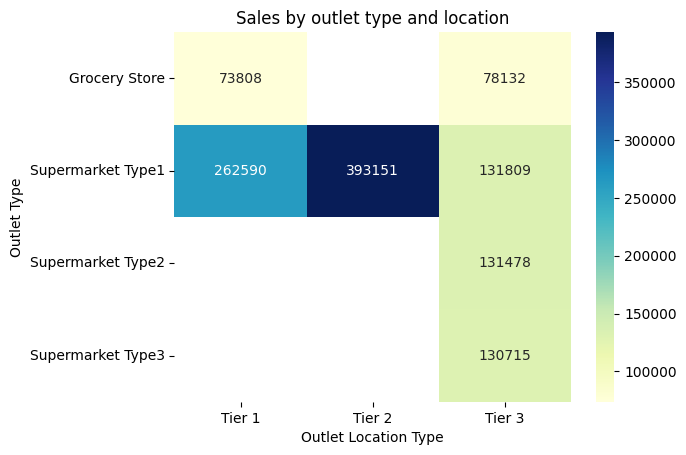

In [79]:
pivot = df.pivot_table(index="Outlet Type", columns="Outlet Location Type", values="Sales", aggfunc="sum")
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="YlGnBu")
plt.title("Sales by outlet type and location")
plt.show()

### Task 4.3 - Where can performance improve

In [80]:
print("Lowest 5 item types by sales")
print(item_sales["sum"].tail(5))
print()
print("Lowest 3 outlets")
print(outlet_sales.tail(3))

Lowest 5 item types by sales
Item Type
Hard Drinks      29334.6806
Others           22451.8916
Starchy Foods    21880.0274
Breakfast        15596.6966
Seafood           9077.8700
Name: sum, dtype: float64

Lowest 3 outlets
Outlet Identifier
OUT017    129103.9604
OUT010     78131.5666
OUT019     73807.5824
Name: Sales, dtype: float64


In [81]:
# products with rating 3 or below
low_rated = df[df["Rating"] <= 3]
print("Low rated rows:", len(low_rated), "out of", len(df))
print(low_rated["Item Type"].value_counts().head(5))

Low rated rows: 617 out of 8523
Item Type
Snack Foods              96
Fruits and Vegetables    92
Frozen Foods             65
Dairy                    51
Household                51
Name: count, dtype: int64


**Observations (Objective 4)**
- Top 5 item types (Fruits and Vegetables, Snack Foods, Household, Frozen Foods, Dairy) give about 59% of the total sales.
- Best outlets are OUT035, OUT046 and OUT013, all of them are Supermarket Type1 and each gives around 130k+. Tier 3 is the best location.
- Weakest areas are Seafood, Breakfast, Others and Starchy Foods, and the two Grocery Store outlets OUT010 and OUT019.
- 617 rows (about 7%) have rating 3 or below, mostly in Snack Foods and Fruits and Vegetables.

### Task 4.4 - Suggestions

1. Keep enough stock of the top selling categories (Fruits and Vegetables, Snack Foods, Household, Frozen Foods, Dairy) because they bring most of the sales.
2. The Grocery Store outlets sell much less than supermarkets. Management should check if they need more product range or should be upgraded.
3. Supermarket Type1 and Tier 3 locations work well, so new outlets can be planned in a similar format.
4. Low selling categories like Seafood and Breakfast can be promoted with offers or combos, or their stock can be reduced to avoid waste.
5. Visibility has no clear effect on sales here, so extra shelf space should be given based on demand, not just to increase visibility.
6. Check the quality of low rated products, especially in Snack Foods and Fruits and Vegetables since they sell a lot.
7. Data entry should be improved: fat content was written in different ways, weight was missing for many rows and visibility was 0 for some products.

## Conclusion
The analysis shows that sales depend mainly on the number of outlets and the kind of products sold, and not on visibility, weight or rating. The top categories and Supermarket Type1 outlets bring most of the sales, while Grocery Stores and some small categories need improvement.